# Deer driver v1: one-class fine-tuning study

This notebook compares identical one-class YOLO26s fine-tuning runs initialized from the existing 26-class wildlife checkpoint and from the official COCO checkpoint. Candidate selection uses only validation mAP50–95. The held-out test split is evaluated once, for the selected candidate only.


In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'scripts').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / 'storage/models/driver_deer'
DATASET_DIR = PROJECT_ROOT / 'data/derived/deer-driver-v1'
SUMMARY_PATH = MODEL_DIR / 'training_summary.json'

assert SUMMARY_PATH.is_file(), 'Run scripts.train_deer_detector first'
summary = json.loads(SUMMARY_PATH.read_text())
summary


{'class_names': ['deer'],
 'dataset': '/home/vivek/Documents/Vivek-projects/WildGuard/data/derived/deer-driver-v1/data.yaml',
 'selected_checkpoint': '/home/vivek/Documents/Vivek-projects/WildGuard/storage/models/driver_deer/best.pt',
 'selected_initialization': 'wildlife',
 'selected_source_checkpoint': '/home/vivek/Documents/Vivek-projects/WildGuard/storage/models/driver_deer/runs/wildlife_init/weights/best.pt',
 'selected_test_metrics': {'map50': 0.8923968014545123,
  'map50_95': 0.6713883022309517,
  'precision': 0.8842274466914218,
  'recall': 0.8468468468468469},
 'selection_metric': 'validation map50_95',
 'settings': {'batch_size': 64,
  'epochs': 60,
  'image_size': 640,
  'patience': 12,
  'seed': 42,
  'smoke_test': False},
 'validation_results': [{'checkpoint': '/home/vivek/Documents/Vivek-projects/WildGuard/storage/models/driver_deer/runs/wildlife_init/weights/best.pt',
   'initialization': 'wildlife',
   'map50': 0.9298552189725784,
   'map50_95': 0.7019030734381442,
   '

## Validation-based model selection and final test result


In [2]:
columns = ('initialization', 'precision', 'recall', 'map50', 'map50_95')
print('Validation candidates')
print(' | '.join(f'{name:>14}' for name in columns))
for row in summary['validation_results']:
    values = [row['initialization']] + [f"{row[name]:.4f}" for name in columns[1:]]
    print(' | '.join(f'{value:>14}' for value in values))

print(f"\nSelected initialization: {summary['selected_initialization']}")
print('Held-out test metrics')
for name, value in summary['selected_test_metrics'].items():
    print(f'{name:>10}: {value:.4f}')


Validation candidates
initialization |      precision |         recall |          map50 |       map50_95
      wildlife |         0.9352 |         0.8943 |         0.9299 |         0.7019
          coco |         0.8992 |         0.8699 |         0.9205 |         0.6776

Selected initialization: wildlife
Held-out test metrics
     map50: 0.8924
  map50_95: 0.6714
 precision: 0.8842
    recall: 0.8468


## Learning curves

The solid line is validation mAP50–95 and the dashed line is validation mAP50. Curves are diagnostic; the final checkpoint choice still follows validation mAP50–95 recorded in the summary.


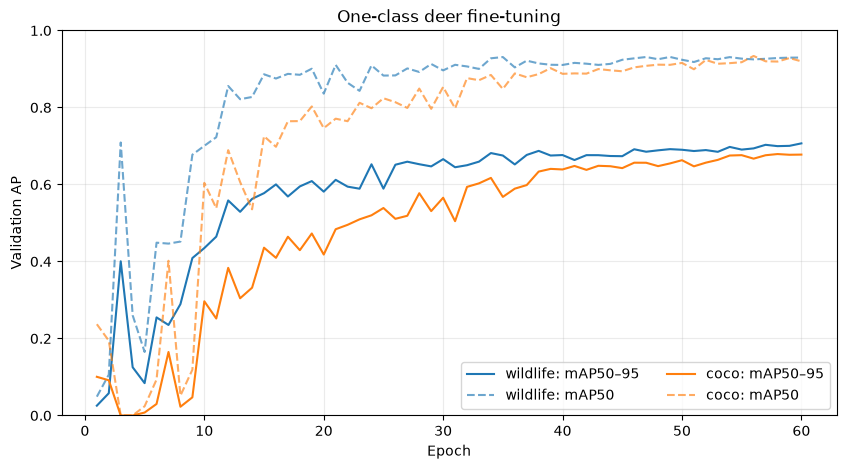

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for initialization in ('wildlife', 'coco'):
    path = MODEL_DIR / 'runs' / f'{initialization}_init' / 'results.csv'
    with path.open(newline='') as handle:
        rows = list(csv.DictReader(handle))
    headers = {name.strip(): name for name in rows[0]}
    epochs = [int(float(row[headers['epoch']])) for row in rows]
    map50 = [float(row[headers['metrics/mAP50(B)']]) for row in rows]
    map50_95 = [float(row[headers['metrics/mAP50-95(B)']]) for row in rows]
    line = ax.plot(epochs, map50_95, label=f'{initialization}: mAP50–95')[0]
    ax.plot(
        epochs,
        map50,
        '--',
        color=line.get_color(),
        alpha=0.65,
        label=f'{initialization}: mAP50',
    )
ax.set(
    xlabel='Epoch',
    ylabel='Validation AP',
    ylim=(0, 1),
    title='One-class deer fine-tuning',
)
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.show()


## Held-out test prediction gallery

A deterministic sample of six positive and six negative test images is shown at confidence 0.25. This is a qualitative error check, not an additional model-selection step.


WARNING ⚠️ NMS time limit 2.050s exceeded


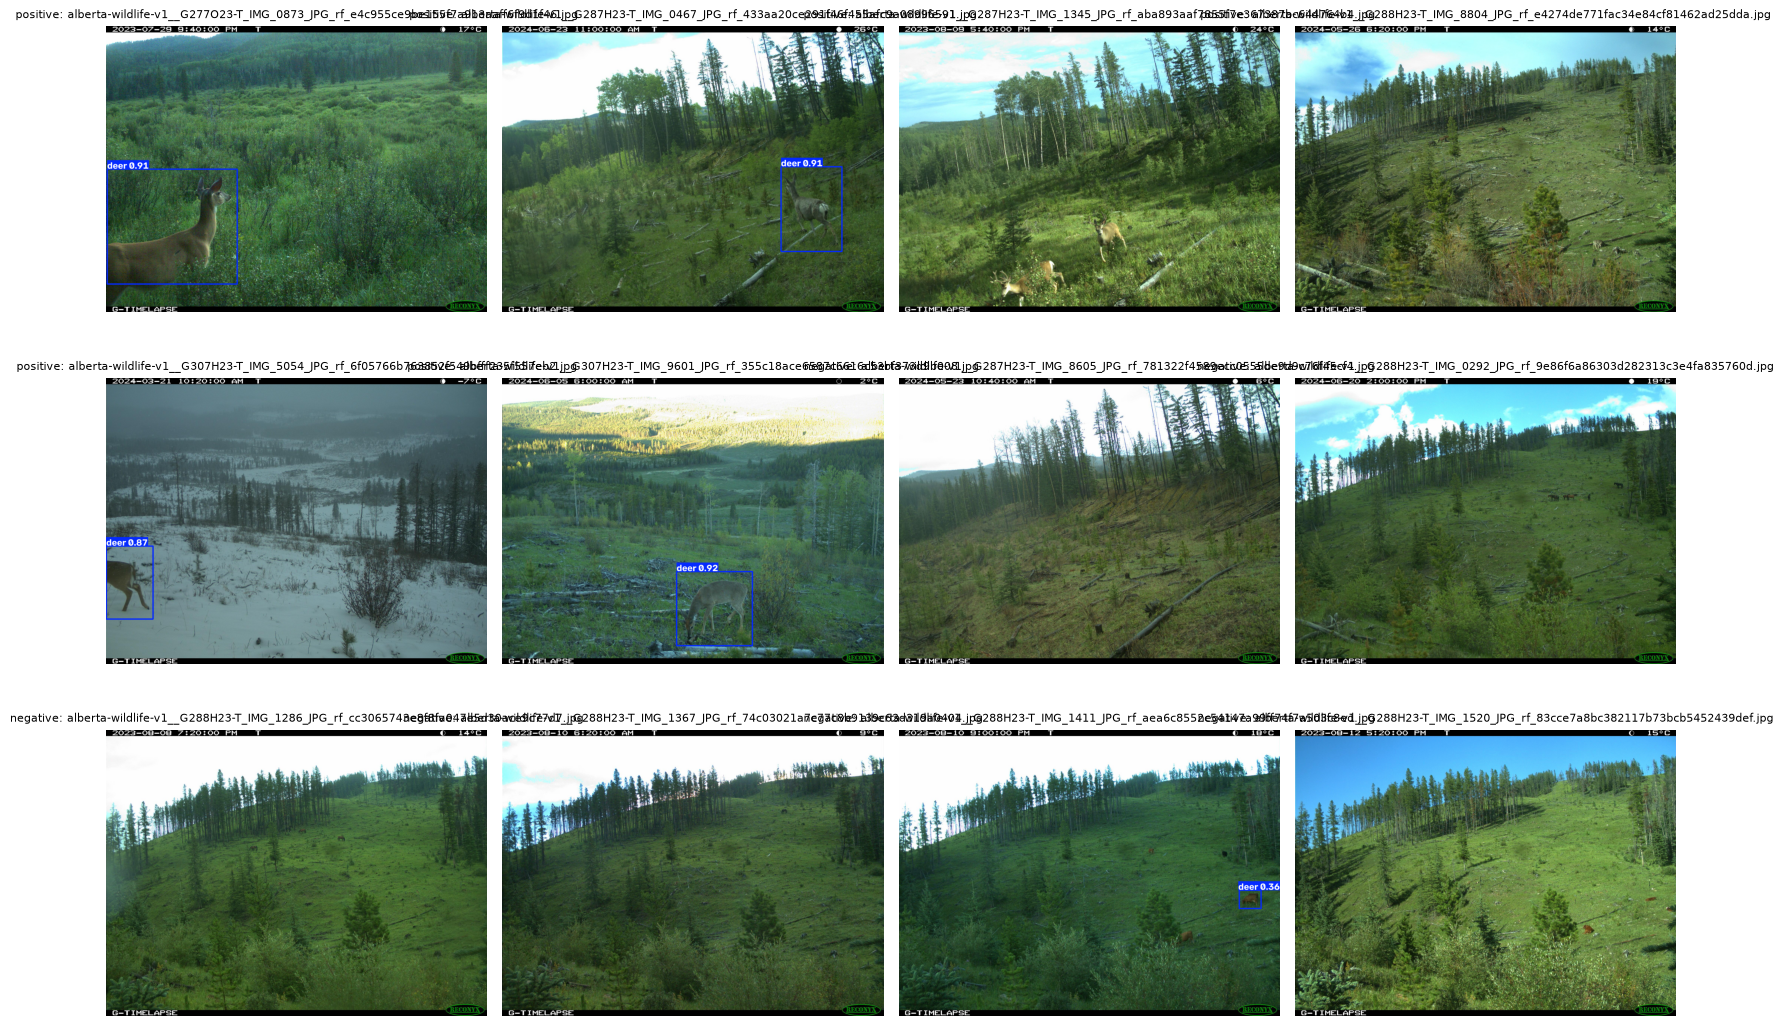

In [4]:
test_images = sorted((DATASET_DIR / 'images/test').glob('*'))
positives, negatives = [], []
for image_path in test_images:
    label_path = DATASET_DIR / 'labels/test' / f'{image_path.stem}.txt'
    target = positives if label_path.read_text().strip() else negatives
    target.append(image_path)
sample = positives[:6] + negatives[:6]
model = YOLO(MODEL_DIR / 'best.pt')
predictions = model.predict(
    sample, imgsz=640, conf=0.25, iou=0.70, device=0, verbose=False
)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, image_path, prediction in zip(axes.flat, sample, predictions, strict=True):
    rendered = Image.fromarray(prediction.plot()[..., ::-1])
    ax.imshow(rendered)
    kind = 'positive' if image_path in positives else 'negative'
    ax.set_title(f'{kind}: {image_path.name}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()


## Interpretation boundaries

- These metrics measure the derived ENA24 + Alberta still-image split, not production road-video safety.
- The one-class label intentionally asks *is this deer?*, avoiding the baseline model's species confusion.
- Before deployment, evaluate independent road/night video by source, lighting, distance, and false alarms per minute; then tune the alert threshold and temporal confirmation policy.
- Do not use the held-out test result for further checkpoint or hyperparameter selection. Create a new validation set for subsequent experiments.
